##Setting up the environment.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle (2).json to kaggle (2).json


{'kaggle (2).json': b'{"username":"aryandave04","key":"ee80676fe4a6ecfd42cd95d6d6bfb376"}'}

In [ ]:
!mv "kaggle (2).json" kaggle.json

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

##Downloading the dataset.

In [ ]:
!kaggle datasets download -d danizo/eeg-dataset-for-adhd -p /content/drive/MyDrive/ADHD_EEG

Dataset URL: https://www.kaggle.com/datasets/danizo/eeg-dataset-for-adhd
License(s): other
eeg-dataset-for-adhd.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip /content/drive/MyDrive/ADHD_EEG/eeg-dataset-for-adhd.zip -d /content/drive/MyDrive/ADHD_EEG

Archive:  /content/drive/MyDrive/ADHD_EEG/eeg-dataset-for-adhd.zip
replace /content/drive/MyDrive/ADHD_EEG/adhdata.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: /content/drive/MyDrive/ADHD_EEG/adhdata.csv  


In [ ]:
import kagglehub
danizo_eeg_dataset_for_adhd_path = kagglehub.dataset_download('danizo/eeg-dataset-for-adhd')

print('Data source import complete.')

100%|██████████| 47.1M/47.1M [00:00<00:00, 127MB/s]

Extracting files...


Data source import complete.


##Fetching the dataset and studying it.

In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/ADHD_EEG/adhdata.csv'
df = pd.read_csv(file_path)

In [ ]:
df.head()

,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,...,F8,T7,T8,P7,P8,Fz,Cz,Pz,Class,ID
0,261.0,402.0,16.0,261.0,126.0,384.0,126.0,236.0,52.0,236.0,...,16.0,200.0,494.0,126.0,236.0,121.0,367.0,121.0,ADHD,v10p
1,121.0,191.0,-94.0,85.0,16.0,200.0,126.0,52.0,347.0,273.0,...,-57.0,126.0,347.0,52.0,52.0,15.0,121.0,-19.0,ADHD,v10p
2,-55.0,85.0,-204.0,15.0,-57.0,200.0,52.0,126.0,236.0,200.0,...,-94.0,126.0,420.0,52.0,126.0,-55.0,261.0,85.0,ADHD,v10p
3,191.0,85.0,52.0,50.0,89.0,236.0,163.0,89.0,89.0,89.0,...,-57.0,236.0,420.0,126.0,126.0,15.0,85.0,-55.0,ADHD,v10p
4,-55.0,-125.0,-204.0,-160.0,-204.0,16.0,-241.0,-241.0,89.0,16.0,...,-131.0,89.0,310.0,-57.0,52.0,-55.0,15.0,-336.0,ADHD,v10p


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2166383 entries, 0 to 2166382
Data columns (total 21 columns):
 #   Column  Dtype  
---  ------  -----  
 0   Fp1     float64
 1   Fp2     float64
 2   F3      float64
 3   F4      float64
 4   C3      float64
 5   C4      float64
 6   P3      float64
 7   P4      float64
 8   O1      float64
 9   O2      float64
 10  F7      float64
 11  F8      float64
 12  T7      float64
 13  T8      float64
 14  P7      float64
 15  P8      float64
 16  Fz      float64
 17  Cz      float64
 18  Pz      float64
 19  Class   object 
 20  ID      object 
dtypes: float64(19), object(2)
memory usage: 347.1+ MB


In [ ]:
df.describe()

,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,O2,F7,F8,T7,T8,P7,P8,Fz,Cz,Pz
count,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06,2.166383e+06
mean,1.360903e+02,1.361619e+02,1.422117e+02,1.361022e+02,1.422737e+02,1.422005e+02,1.422755e+02,1.419608e+02,1.419823e+02,1.416007e+02,1.420600e+02,1.415633e+02,1.417452e+02,1.413199e+02,1.416635e+02,1.410618e+02,1.352097e+02,1.351830e+02,1.352074e+02
std,2.755497e+02,2.755136e+02,2.206503e+02,2.133873e+02,2.234852e+02,2.107195e+02,2.301860e+02,2.095699e+02,2.360460e+02,2.133996e+02,2.432087e+02,2.265186e+02,2.272337e+02,2.273205e+02,2.079590e+02,2.048027e+02,2.522447e+02,2.130295e+02,2.274500e+02
min,-3.786000e+03,-1.322400e+04,-3.921000e+03,-1.323700e+04,-3.921000e+03,-3.921000e+03,-3.921000e+03,-3.958000e+03,-3.995000e+03,-3.921000e+03,-3.995000e+03,-3.958000e+03,-3.958000e+03,-3.995000e+03,-3.921000e+03,-3.958000e+03,-3.786000e+03,-3.751000e+03,-3.751000e+03
25%,1.500000e+01,1.500000e+01,5.200000e+01,1.500000e+01,5.200000e+01,5.200000e+01,1.600000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,5.200000e+01,1.500000e+01,1.500000e+01,1.500000e+01
50%,1.210000e+02,1.210000e+02,1.260000e+02,1.210000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.260000e+02,1.210000e+02,1.210000e+02,1.210000e+02
75%,2.610000e+02,2.260000e+02,2.360000e+02,2.260000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.360000e+02,2.610000e+02,2.260000e+02,2.260000e+02
max,1.381300e+04,4.802000e+03,5.020000e+03,4.802000e+03,5.430000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.020000e+03,5.064000e+03,5.016000e+03,5.020000e+03,4.802000e+03,4.802000e+03,4.802000e+03


array([[<Axes: title={'center': 'Fp1'}>, <Axes: title={'center': 'Fp2'}>,
        <Axes: title={'center': 'F3'}>, <Axes: title={'center': 'F4'}>],
       [<Axes: title={'center': 'C3'}>, <Axes: title={'center': 'C4'}>,
        <Axes: title={'center': 'P3'}>, <Axes: title={'center': 'P4'}>],
       [<Axes: title={'center': 'O1'}>, <Axes: title={'center': 'O2'}>,
        <Axes: title={'center': 'F7'}>, <Axes: title={'center': 'F8'}>],
       [<Axes: title={'center': 'T7'}>, <Axes: title={'center': 'T8'}>,
        <Axes: title={'center': 'P7'}>, <Axes: title={'center': 'P8'}>],
       [<Axes: title={'center': 'Fz'}>, <Axes: title={'center': 'Cz'}>,
        <Axes: title={'center': 'Pz'}>, <Axes: >]], dtype=object)

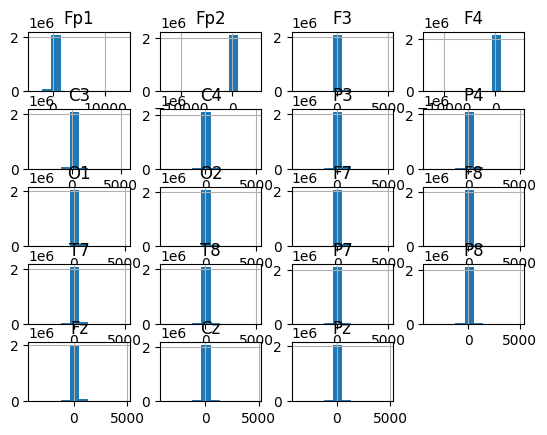

In [ ]:
df.hist()

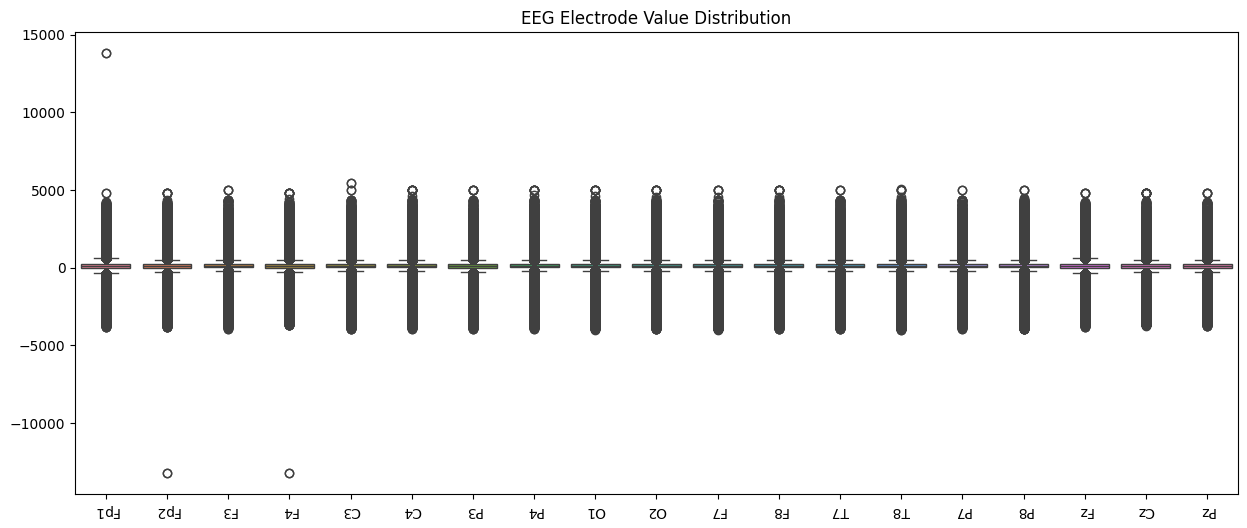

In [ ]:
electrodes = df.columns[:-2]      # remove Class and ID

plt.figure(figsize=(15,6))
sns.boxplot(data=df[electrodes])
plt.xticks(rotation=180)
plt.title("EEG Electrode Value Distribution")
plt.show()

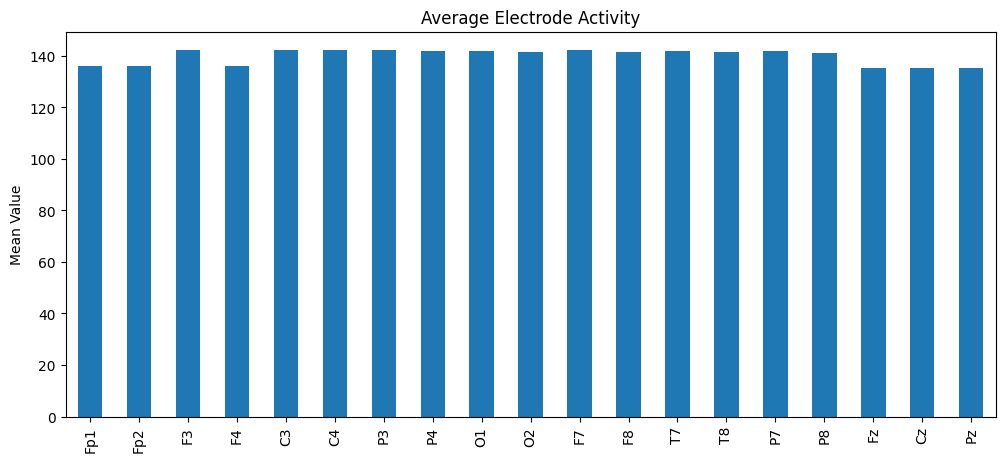

In [ ]:
means = df[electrodes].mean()

plt.figure(figsize=(12,5))
means.plot(kind='bar')
plt.ylabel("Mean Value")
plt.title("Average Electrode Activity")
plt.show()

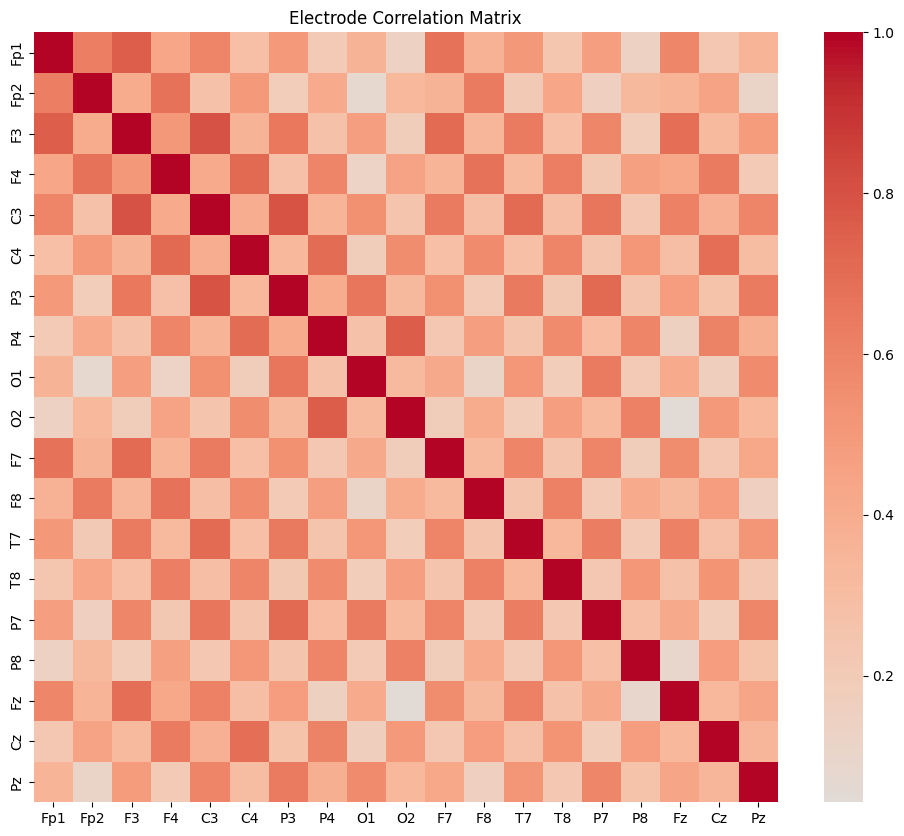

In [ ]:
plt.figure(figsize=(12,10))
sns.heatmap(
    df[electrodes].corr(),
    cmap='coolwarm',
    center=0
)
plt.title("Electrode Correlation Matrix")
plt.show()

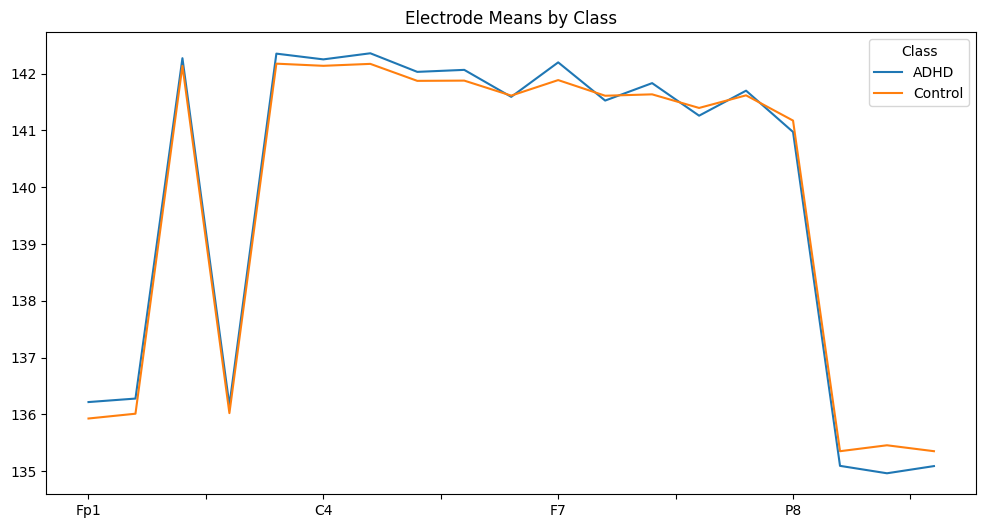

In [ ]:
group_mean = df.groupby('Class')[electrodes].mean()

group_mean.T.plot(figsize=(12,6))
plt.title("Electrode Means by Class")
plt.show()

<Axes: >

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


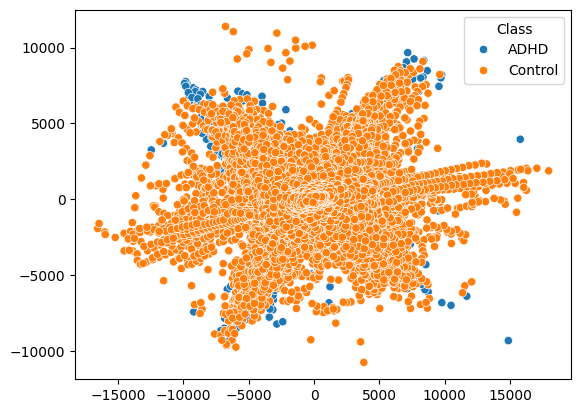

In [ ]:
from sklearn.decomposition import PCA

X = df[electrodes]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df['Class']
)

##Importing required libraries.

In [ ]:
!pip install antropy
!pip install nolds

In [ ]:
import numpy as np
import pandas as pd
import antropy as ant
import pywt
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import nolds
from scipy.stats import skew, kurtosis
from scipy.signal import welch, hilbert, csd

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

##Selecting the properties for training the model.

In [ ]:
SELECTED_CHANNELS = ['F3','F4','Fz','P3','P4','Pz','O1','O2']
SF = 128
WINDOW_LEN = SF*2

# Writing functions for extracting features.

In [ ]:
def calculate_wpli(sig1,sig2):
  f, Pxy = csd(sig1, sig2, fs=128, nperseg=128)
  imag_pxy = np.imag(Pxy)
  return np.abs(np.mean(imag_pxy)) / (np.mean(np.abs(imag_pxy)) + 1e-6)

In [ ]:
def extract_wavelet_features(sig):
  coeffs = pywt.wavedec(sig, 'db4', level=4)
  return [np.sum(np.square(c)) for c in coeffs]

In [ ]:
def wavelet_entropy(sig):
    coeffs = pywt.wavedec(sig, 'db4', level=4)
    energy = np.array([np.sum(c**2) for c in coeffs])
    prob = energy / (np.sum(energy) + 1e-6)
    return -np.sum(prob * np.log(prob + 1e-6))

In [ ]:
def wavelet_entropy(sig):
    coeffs = pywt.wavedec(sig, 'db4', level=4)
    energy = np.array([np.sum(c**2) for c in coeffs])
    prob = energy / (np.sum(energy) + 1e-6)
    return -np.sum(prob * np.log(prob + 1e-6))

In [ ]:
def corr_dimension(sig):
    try:
        return nolds.corr_dim(sig, emb_dim=5)
    except:
        return 0

In [ ]:
def lyapunov_exp(sig):
    try:
        return nolds.lyap_r(sig)
    except:
        return 0

In [ ]:
def katz_fd(sig):
    L = np.sum(np.abs(np.diff(sig)))
    d = np.max(np.abs(sig - sig[0]))
    n = len(sig)
    return np.log10(n) / (np.log10(d / L + 1e-6) + np.log10(n))

In [ ]:
def petrosian_fd(sig):
    diff = np.diff(sig)
    N = len(sig)
    N_delta = np.sum(diff[:-1] * diff[1:] < 0)
    return np.log10(N) / (np.log10(N) + np.log10(N / (N + 0.4 * N_delta)))

In [ ]:
def add_connectivity(eeg_data):
    pairs = [('F3', 'F4'), ('P3', 'P4'), ('Fz', 'Pz'), ('O1', 'O2')]
    conn_feats = []
    for p1, p2 in pairs:
        idx1, idx2 = SELECTED_CHANNELS.index(p1), SELECTED_CHANNELS.index(p2)
        conn_feats.append(calculate_wpli(eeg_data[idx1], eeg_data[idx2]))
    return conn_feats

In [ ]:
def add_connectivity(eeg_data):
    # Defining specific biologically relevant pairs
    pairs = [('F3', 'F4'), ('P3', 'P4'), ('Fz', 'Pz'), ('O1', 'O2')]
    conn_feats = []
    for p1, p2 in pairs:
        try:
            idx1, idx2 = SELECTED_CHANNELS.index(p1), SELECTED_CHANNELS.index(p2)
            conn_feats.append(calculate_wpli(eeg_data[idx1], eeg_data[idx2]))
        except ValueError:
            continue
    return conn_feats

def extract_all_features(eeg_data, SF):
    all_features = []
    ch_metrics = {}

    for i, ch_name in enumerate(SELECTED_CHANNELS):
        sig = eeg_data[i]

        # 1. Statistical Features
        all_features.extend([np.mean(sig), np.std(sig), np.var(sig), skew(sig), kurtosis(sig)])

        # 2. Bandpower (Welch)
        freqs, psd = welch(sig, SF, nperseg=SF)
        def bp(low, high):
            idx = np.logical_and(freqs >= low, freqs <= high)
            return np.trapezoid(psd[idx], freqs[idx])

        t, a, b = bp(4, 8), bp(8, 13), bp(13, 30)
        ch_metrics[ch_name] = {"t": t, "a": a, "b": b}

        # Adding Ratios per channel (Crucial for ADHD)
        tbr = t / (b + 1e-6) # Theta-Beta Ratio
        tar = t / (a + 1e-6) # Theta-Alpha Ratio
        all_features.extend([t, a, b, tbr, tar])

        # 3. Non-Linear Complexity
        hfd = ant.higuchi_fd(sig)
        se = ant.spectral_entropy(sig, SF, method='welch')
        ch_metrics[ch_name].update({'hfd': hfd, 'se': se})
        all_features.extend([hfd, se, ant.sample_entropy(sig)])

        # 4. Wavelet Features
        all_features.extend(extract_wavelet_features(sig))
        all_features.append(wavelet_entropy(sig))

        # 5. Fractal Dimensions
        all_features.extend([katz_fd(sig), petrosian_fd(sig)])

        # 6. Hjorth Parameters
        activity = np.var(sig)
        diff1 = np.diff(sig)
        mobility = np.std(diff1) / (np.std(sig) + 1e-6)
        diff2 = np.diff(diff1)
        complexity = (np.std(diff2) / (np.std(diff1) + 1e-6)) / (mobility + 1e-6)
        all_features.extend([activity, mobility, complexity])

    # 7. Connectivity (Flattened)
    # Use .extend() instead of .append() to keep the array 1D
    connectivity_values = add_connectivity(eeg_data)
    all_features.extend(connectivity_values)

    # 8. Cross-Channel Interactions
    fz_comp_ratio = ch_metrics['Fz']['hfd'] / (ch_metrics['Fz']['t'] + 1e-6)
    fp_interact = ch_metrics['Fz']['hfd'] * ch_metrics['Pz']['se']
    # Frontal Alpha Asymmetry (FAA)
    faa = np.log(ch_metrics['F4']['a'] + 1e-6) - np.log(ch_metrics['F3']['a'] + 1e-6)

    all_features.extend([fz_comp_ratio, fp_interact, faa])

    return np.array(all_features)

## Extracting Features:

In [ ]:
subjects = df['ID'].unique()

X,y,groups = [],[],[]

for sub in tqdm(subjects):
  sub_df = df[df['ID'] == sub]
  label = 1 if "ADHD" in str(sub_df['Class'].iloc[0]).upper() else 0
  raw_data = sub_df[SELECTED_CHANNELS].values

  STEP = WINDOW_LEN//2
  STEP = WINDOW_LEN + STEP

  for start in range(0,len(raw_data)-WINDOW_LEN,STEP):
    win = raw_data[start:start+WINDOW_LEN].T
    X.append(extract_all_features(win,SF))
    y.append(label)
    groups.append(sub)

X,y,groups = np.array(X), np.array(y), np.array(groups)

100%|██████████| 121/121 [03:28<00:00,  1.72s/it]


## Validating Data

In [ ]:
import numpy as np
import pandas as pd

X_full = np.asarray(X, dtype=np.float64)
y = np.asarray(y).ravel().astype(int)
groups = np.asarray(groups).ravel()

print("X:", X_full.shape)
print("y:", y.shape)
print("groups:", groups.shape)

assert len(X_full) == len(y) == len(groups)

print("\nClasses:", np.unique(y, return_counts=True))
print("Unique participants:", np.unique(groups).size)

# Check that each participant has exactly one label
subject_labels = pd.DataFrame({
    "subject": groups,
    "label": y
})

label_counts = subject_labels.groupby("subject")["label"].nunique()

print("Participants with inconsistent labels:",
      (label_counts > 1).sum())

assert (label_counts <= 1).all()

# Check missing and infinite values
print("NaN values:", np.isnan(X_full).sum())
print("Infinite values:", np.isinf(X_full).sum())

# Replace infinities with NaN; handle them later in the pipeline
X_full[~np.isfinite(X_full)] = np.nan

# Check class distribution at participant level
subjects = subject_labels.drop_duplicates("subject")

print("\nParticipant-level class distribution:")
print(subjects["label"].value_counts())

# Epochs per participant
epochs_per_subject = subject_labels.groupby("subject").size()

print("\nEpochs per participant:")
print(epochs_per_subject.describe())

X: (5621, 199)
y: (5621,)
groups: (5621,)

Classes: (array([0, 1]), array([2487, 3134]))
Unique participants: 121
Participants with inconsistent labels: 0
NaN values: 0
Infinite values: 0

Participant-level class distribution:
label
1    61
0    60
Name: count, dtype: int64

Epochs per participant:
count    121.000000
mean      46.454545
std       16.147239
min       21.000000
25%       36.000000
50%       43.000000
75%       52.000000
max      112.000000
dtype: float64


## Creating Multi-Domain feature and Spectral Feature Sets

In [ ]:
SELECTED_CHANNELS = [
    'F3', 'F4', 'Fz', 'P3',
    'P4', 'Pz', 'O1', 'O2'
]

features_per_channel = 24

# Spectral feature positions within each channel
spectral_positions = [5, 6, 7, 8, 9]

spectral_indices = []

for ch in range(len(SELECTED_CHANNELS)):
    for pos in spectral_positions:
        spectral_indices.append(
            ch * features_per_channel + pos
        )


# Extract spectral features
X_spectral = X_full[:, spectral_indices]

# Complete multi-domain representation
X_multidomain = X_full.copy()

print("Spectral shape:", X_spectral.shape)
print("Multi-domain shape:", X_multidomain.shape)

Spectral shape: (5621, 40)
Multi-domain shape: (5621, 199)


## Training and Comparing ML Models

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/predictions", exist_ok=True)

In [ ]:
def make_model(name, n_features):

    k = min(25, n_features)

    if name == "Dummy":

        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('classifier', DummyClassifier(
                strategy='prior'
            ))
        ])

    if name == "Logistic Regression":

        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),

            ('selector', SelectKBest(
                score_func=f_classif,
                k=k
            )),

            ('scaler', StandardScaler()),

            ('classifier', LogisticRegression(
                C=1.0,
                max_iter=3000,
                class_weight='balanced',
                random_state=42
            ))
        ])

    if name == "Random Forest":

        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),

            ('selector', SelectKBest(
                score_func=f_classif,
                k=k
            )),

            ('classifier', RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                class_weight='balanced_subsample',
                random_state=42,
                n_jobs=-1
            ))
        ])

    if name == "SVM":

        # Probability calibration will be performed separately
        # with participant-grouped internal folds.
        return Pipeline([
            ('imputer', SimpleImputer(strategy='median')),

            ('selector', SelectKBest(
                score_func=f_classif,
                k=k
            )),

            ('scaler', StandardScaler()),

            ('classifier', SVC(
                C=1.0,
                kernel='rbf',
                gamma='scale',
                probability=False,
                class_weight='balanced'
            ))
        ])

    raise ValueError("Unknown model")

In [ ]:
def fit_model(name, X_train, y_train, groups_train):

    if name != "SVM":

        model = make_model(
            name,
            X_train.shape[1]
        )

        model.fit(X_train, y_train)

        return model

    # SVM base pipeline
    base_svm = make_model(
        "SVM",
        X_train.shape[1]
    )

    # Group-aware internal calibration
    inner_cv = GroupKFold(n_splits=3)

    inner_splits = list(
        inner_cv.split(
            X_train,
            y_train,
            groups=groups_train
        )
    )

    calibrated_svm = CalibratedClassifierCV(
        estimator=base_svm,
        method='sigmoid',
        cv=inner_splits,
        ensemble=False
    )

    calibrated_svm.fit(X_train, y_train)

    return calibrated_svm

In [ ]:
def calculate_metrics(y_true, scores):

    y_pred = (scores >= 0.5).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Balanced Accuracy":
            balanced_accuracy_score(y_true, y_pred),

        "Sensitivity":
            recall_score(y_true, y_pred, pos_label=1),

        "Specificity":
            recall_score(y_true, y_pred, pos_label=0),

        "Precision":
            precision_score(y_true, y_pred, zero_division=0),

        "Macro F1":
            f1_score(y_true, y_pred, average='macro'),

        "ROC AUC":
            roc_auc_score(y_true, scores)
    }

In [ ]:
feature_sets = {
    "Spectral": X_spectral,
    "Multi-domain": X_multidomain
}

models = [
    "Dummy",
    "Logistic Regression",
    "Random Forest",
    "SVM"
]

outer_cv = GroupKFold(n_splits=5)

all_results = []
all_predictions = {}

for feature_name, X_data in feature_sets.items():

    print("\nFEATURE SET:", feature_name)

    for model_name in models:

        print("\nRunning:", model_name)

        oof_probabilities = np.full(
            len(y), np.nan
        )

        fold_results = []

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X_data, y, groups)
        ):

            X_train = X_data[train_idx]
            X_test = X_data[test_idx]

            y_train = y[train_idx]
            y_test = y[test_idx]

            groups_train = groups[train_idx]
            groups_test = groups[test_idx]

            # Explicit leakage check
            assert set(groups_train).isdisjoint(
                set(groups_test)
            )

            assert len(np.unique(y_train)) == 2

            model = fit_model(
                model_name,
                X_train,
                y_train,
                groups_train
            )

            # ADHD probability
            probabilities = model.predict_proba(
                X_test
            )[:, list(model.classes_).index(1)]

            oof_probabilities[test_idx] = probabilities

            # Aggregate epochs to participant level
            fold_df = pd.DataFrame({
                "Subject": groups_test,
                "True": y_test,
                "Probability": probabilities
            })

            subject_fold = (
                fold_df
                .groupby("Subject")
                .agg({
                    "True": "first",
                    "Probability": "mean"
                })
                .reset_index()
            )

            # Verify label consistency
            assert (
                fold_df.groupby("Subject")["True"].nunique()
                .max() == 1
            )

            fold_metrics = calculate_metrics(
                subject_fold["True"].values,
                subject_fold["Probability"].values
            )

            fold_metrics["Fold"] = fold + 1

            fold_results.append(fold_metrics)

        assert np.isfinite(oof_probabilities).all()

        # Final out-of-fold participant-level predictions
        pred_df = pd.DataFrame({
            "Subject": groups,
            "True": y,
            "Probability": oof_probabilities
        })

        subject_predictions = (
            pred_df
            .groupby("Subject")
            .agg({
                "True": "first",
                "Probability": "mean"
            })
            .reset_index()
        )

        subject_predictions["Predicted"] = (
            subject_predictions["Probability"] >= 0.5
        ).astype(int)

        final_metrics = calculate_metrics(
            subject_predictions["True"].values,
            subject_predictions["Probability"].values
        )

        fold_df = pd.DataFrame(fold_results)

        result = {
            "Feature Set": feature_name,
            "Model": model_name,
            **final_metrics,
            "Fold Balanced Accuracy Mean":
                fold_df["Balanced Accuracy"].mean(),
            "Fold Balanced Accuracy SD":
                fold_df["Balanced Accuracy"].std()
        }

        all_results.append(result)

        key = (feature_name, model_name)

        all_predictions[key] = subject_predictions.copy()

        subject_predictions.to_csv(
            f"results/predictions/"
            f"{feature_name}_{model_name.replace(' ', '_')}.csv",
            index=False
        )

        print(final_metrics)


results_df = pd.DataFrame(all_results)

results_df.to_csv(
    "results/metrics.csv",
    index=False
)

print("\nFINAL COMPARISON")
display(results_df.round(4))


FEATURE SET: Spectral

Running: Dummy
{'Accuracy': 0.5041322314049587, 'Balanced Accuracy': np.float64(0.5), 'Sensitivity': 1.0, 'Specificity': 0.0, 'Precision': 0.5041322314049587, 'Macro F1': 0.33516483516483514, 'ROC AUC': np.float64(0.3498633879781421)}

Running: Logistic Regression
{'Accuracy': 0.6033057851239669, 'Balanced Accuracy': np.float64(0.6025956284153006), 'Sensitivity': 0.6885245901639344, 'Specificity': 0.5166666666666667, 'Precision': 0.5915492957746479, 'Macro F1': 0.6, 'ROC AUC': np.float64(0.6442622950819672)}

Running: Random Forest
{'Accuracy': 0.6446280991735537, 'Balanced Accuracy': np.float64(0.64275956284153), 'Sensitivity': 0.8688524590163934, 'Specificity': 0.4166666666666667, 'Precision': 0.6022727272727273, 'Macro F1': 0.6245219022876525, 'ROC AUC': np.float64(0.6948087431693989)}

Running: SVM
{'Accuracy': 0.5785123966942148, 'Balanced Accuracy': np.float64(0.5762295081967213), 'Sensitivity': 0.8524590163934426, 'Specificity': 0.3, 'Precision': 0.553191

,Feature Set,Model,Accuracy,Balanced Accuracy,Sensitivity,Specificity,Precision,Macro F1,ROC AUC,Fold Balanced Accuracy Mean,Fold Balanced Accuracy SD
0,Spectral,Dummy,0.5041,0.5000,1.0000,0.0000,0.5041,0.3352,0.3499,0.5000,0.0000
1,Spectral,Logistic Regression,0.6033,0.6026,0.6885,0.5167,0.5915,0.6000,0.6443,0.6293,0.0304
2,Spectral,Random Forest,0.6446,0.6428,0.8689,0.4167,0.6023,0.6245,0.6948,0.6751,0.1157
3,Spectral,SVM,0.5785,0.5762,0.8525,0.3000,0.5532,0.5424,0.6216,0.6258,0.0415
4,Multi-domain,Dummy,0.5041,0.5000,1.0000,0.0000,0.5041,0.3352,0.3499,0.5000,0.0000
5,Multi-domain,Logistic Regression,0.7769,0.7764,0.8361,0.7167,0.7500,0.7759,0.8003,0.7754,0.0706
6,Multi-domain,Random Forest,0.7769,0.7766,0.8033,0.7500,0.7656,0.7766,0.8626,0.7709,0.0656
7,Multi-domain,SVM,0.7769,0.7760,0.8852,0.6667,0.7297,0.7738,0.8372,0.7773,0.0690


In [ ]:
print("hello")

hello


# Participant Class Distribution

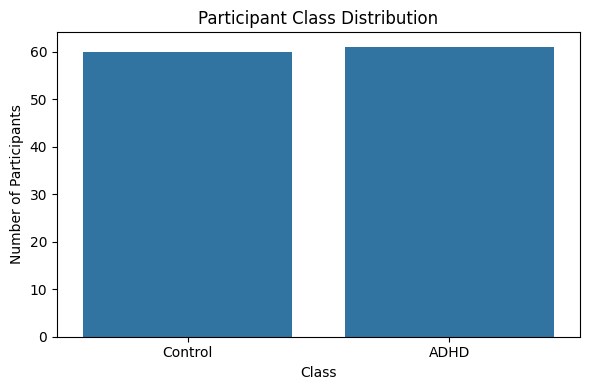

In [ ]:
subject_data = pd.DataFrame({
    "Subject": groups,
    "Label": y
}).drop_duplicates("Subject")

plt.figure(figsize=(6, 4))

sns.countplot(
    data=subject_data,
    x="Label"
)

plt.xticks([0, 1], ["Control", "ADHD"])
plt.title("Participant Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.savefig("results/figures/class_distribution.png")
plt.show()

# Number of epochs per participant

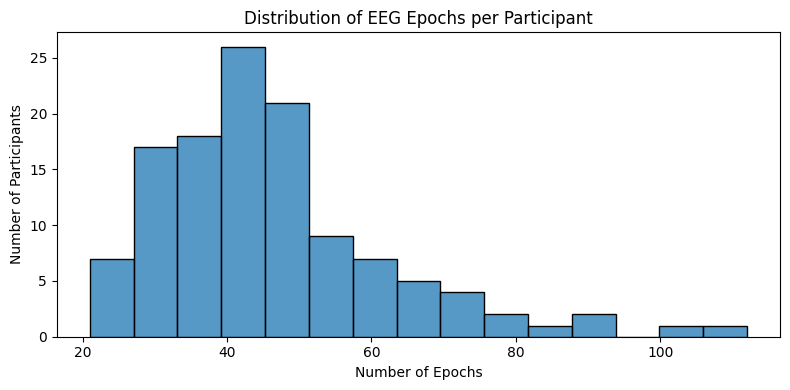

In [ ]:
epoch_counts = pd.Series(groups).value_counts()

plt.figure(figsize=(8, 4))

sns.histplot(epoch_counts, bins=15)

plt.title("Distribution of EEG Epochs per Participant")
plt.xlabel("Number of Epochs")
plt.ylabel("Number of Participants")

plt.tight_layout()
plt.savefig("results/figures/epochs_per_subject.png")
plt.show()

# ROC Curves

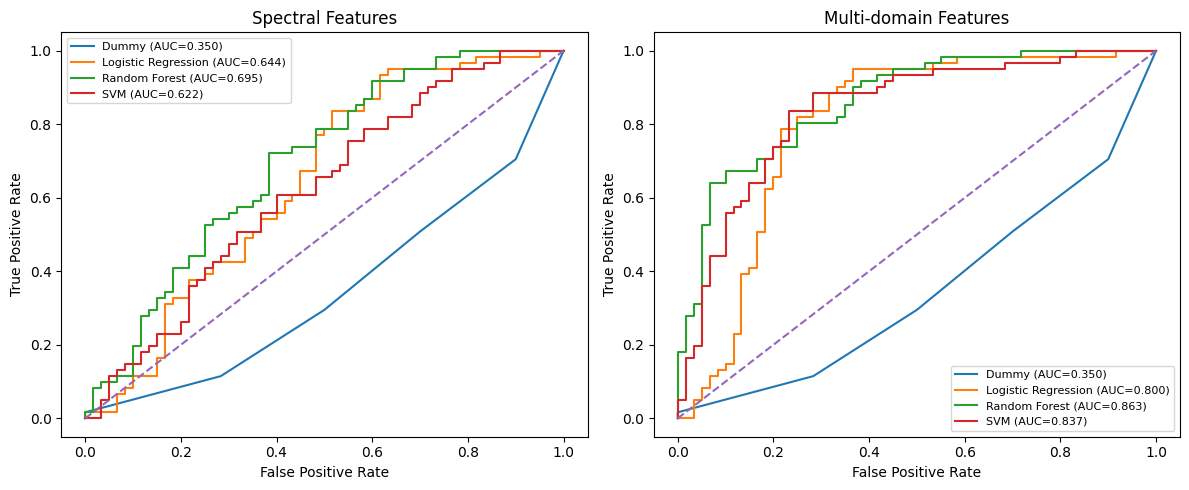

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature_name in zip(
    axes, ["Spectral", "Multi-domain"]
):

    for model_name in models:

        pred = all_predictions[
            (feature_name, model_name)
        ]

        fpr, tpr, _ = roc_curve(
            pred["True"],
            pred["Probability"]
        )

        auc = roc_auc_score(
            pred["True"],
            pred["Probability"]
        )

        ax.plot(
            fpr,
            tpr,
            label=f"{model_name} (AUC={auc:.3f})"
        )

    ax.plot([0, 1], [0, 1], linestyle="--")

    ax.set_title(f"{feature_name} Features")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/figures/roc_comparison.png")
plt.show()

# Confusion Matrix of the best cross-validated model

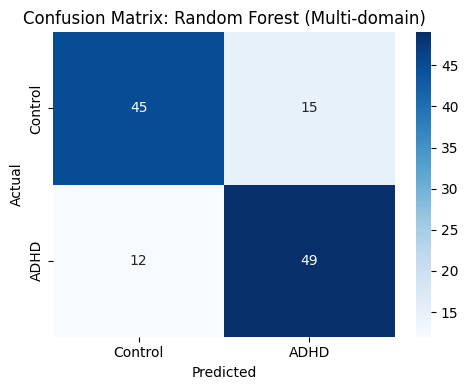

In [ ]:
best = results_df.sort_values(
    "Balanced Accuracy",
    ascending=False
).iloc[0]

key = (
    best["Feature Set"],
    best["Model"]
)

pred = all_predictions[key]

cm = confusion_matrix(
    pred["True"],
    pred["Predicted"]
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Control", "ADHD"],
    yticklabels=["Control", "ADHD"]
)

plt.title(
    f"Confusion Matrix: {best['Model']} "
    f"({best['Feature Set']})"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.savefig("results/figures/best_confusion_matrix.png")
plt.show()

In [ ]:
print(X_full.shape)
print(X_spectral.shape)
print(np.unique(groups).size)
print(pd.Series(y).value_counts())

(5621, 199)
(5621, 40)
121
1    3134
0    2487
Name: count, dtype: int64


## Applying KMeans to find the best 25 features:

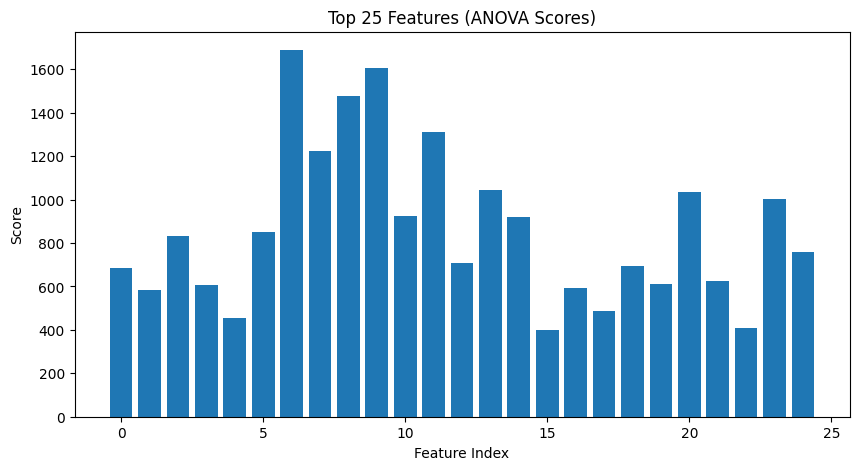

Top 25 Feature Indices: [ 10  11  20  22  34  44  58  59  68  70  82  83  91  92  94 106 116 121
 130 131 140 142 155 164 188]
Top 25 features: [ 686.66286467  583.60487216  830.59257017  608.01718012  452.97080849
  849.00748355 1688.73431178 1223.8098071  1477.97776589 1607.83079322
  925.06558682 1313.15420779  708.94418278 1042.77315049  920.40023774
  399.36557536  592.11566684  485.90169367  693.37607458  609.41557524
 1035.93770079  627.25517729  409.66239833 1004.30521422  756.61083655]


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

k = 25
selector = SelectKBest(score_func=f_classif, k=k)
X_selected = selector.fit_transform(X, y)

selected_indices = selector.get_support(indices=True)
scores = selector.scores_

# Visualize top 25
top_features = scores[selected_indices]

plt.figure(figsize=(10,5))
plt.bar(range(len(top_features)), top_features)
plt.title('Top 25 Features (ANOVA Scores)')
plt.xlabel('Feature Index')
plt.ylabel('Score')
plt.show()

print("Top 25 Feature Indices:", selected_indices)
print("Top 25 features:", scores[selected_indices])

## Applying PCA:

In [ ]:
from sklearn.decomposition import PCA

variances = [0.80, 0.85, 0.90, 0.95]

for var in variances:
    pca = PCA(n_components=var)
    X_pca = pca.fit_transform(X)

    print(f"\nExplained Variance: {var}")
    print(f"Reduced Dimensions: {X_pca.shape[1]}")


Explained Variance: 0.8
Reduced Dimensions: 2

Explained Variance: 0.85
Reduced Dimensions: 3

Explained Variance: 0.9
Reduced Dimensions: 4

Explained Variance: 0.95
Reduced Dimensions: 7
